# Integrated HPP-DC lifetime finance validation

Validate standalone Phase 1 finance and the integrated OpenMDAO assembly using the saved EUR 800/MWh IT, 99.9% reference design. The assembly replays the archived dispatch and recomputes native generation, costs and finance. No CPLEX solve or EGO search is run. All financial assumptions come from the shared YAML with optional overrides below.


In [17]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from hydesign.sizing_native_hpp_sizing_base import ROOT, read_configuration, _output_path
from hydesign.finance.finance_simple_datacenter import (
    FINANCE_PARAMETERS, ASSETS, evaluate_saved_finance, compare_native_hpp_finance)

# Configuration: edit paths or add financial sensitivity overrides here.
config_path = ROOT / 'hydesign/examples/thesis_simple_datacenter/simple_datacenter.yml'
""" reference_result = _output_path(
    ROOT / 'hpp_sizing_runs/joint_hpp_dc_sizing/revenue_batch_20261117_223745Z_ddca96b6'
    / 'scenario_01_revenue_800_eur_per_mwh_it/20261117_223745Z_52236fea_joint_hpp_dc_sizing/result.json')
 """
""" reference_result = _output_path(
    ROOT / 'hpp_sizing_runs/joint_hpp_dc_sizing/'
    'revenue_batch_20261117_223745Z_ddca96b6/'
    'scenario_01_revenue_800_eur_per_mwh_it/'
    '20261117_223745Z_52236fea_joint_hpp_dc_sizing/result.json'
) """
reference_result = _output_path(
    ROOT / 'hpp_sizing_runs/joint_hpp_dc_sizing/'
    'revenue_batch_20261116_213554Z_0f8370a8/'
    'scenario_09_revenue_4000_eur_per_mwh_it/'
    '20261117_033351Z_af257c61_joint_hpp_dc_sizing/result.json'
)
config = read_configuration(config_path)
saved_configuration = json.loads(reference_result.read_text(encoding='utf8'))['configuration']
financial_overrides = {
    # Use this reference scenario's revenue; all other current inputs come from YAML.
    'datacenter_firm_revenue_per_mwh_it': saved_configuration['datacenter_firm_revenue_per_mwh_it'],
}


In [18]:
case = evaluate_saved_finance(reference_result, config, financial_overrides)
finance = case['finance']
effective = case['configuration']
design = case['design']
metrics = case['metrics']

display(pd.DataFrame([{
    'Wind [MW]': design[2] * design[3], 'Turbines': design[3],
    'PV [MW AC]': design[5], 'Battery [MW]': design[9],
    'Battery [MWh]': design[9] * design[10], 'IT [MW]': design[-1],
    'Facility [MW]': design[-1] * effective['pue'],
    'Reference target [%]': 100 * case['saved_configuration']['reliability_target'],
    'Reliability [%]': 100 * metrics['firm_reliability'], 'LOLH [h]': metrics['LOLH'],
    'EENS [MWh facility]': metrics['EENS'],
    'Served IT [MWh/year]': case['served_it_energy_mwh'],
}]))
print('Saved dispatch checksum, physical balances, reliability and original economics verified.')


,Wind [MW],Turbines,PV [MW AC],Battery [MW],Battery [MWh],IT [MW],Facility [MW],Reference target [%],Reliability [%],LOLH [h],EENS [MWh facility],Served IT [MWh/year]
0,300.0,60.0,232.61,80.0,1200.0,33.197723,38.177381,99.9,99.908676,8.0,286.745795,290562.705294


Saved dispatch checksum, physical balances, reliability and original economics verified.


In [19]:
assumption_names = list(FINANCE_PARAMETERS) + [
    'wind_WACC', 'solar_WACC', 'battery_WACC', 'datacenter_discount_rate',
    'datacenter_firm_revenue_per_mwh_it', 'N_life']
display(pd.DataFrame({
    'Assumption': assumption_names,
    'Effective value': [str(effective[name]) for name in assumption_names],
}))


,Assumption,Effective value
0,hpp_economic_lifetime_years,25
1,wind_life_y,25
2,solar_life_y,25
3,battery_life_y,15
4,shared_life_y,25
5,datacenter_facility_lifetime_years,25
6,datacenter_it_lifetime_years,5
7,project_discount_rate,0.07
8,tax_rate,0.0
9,battery_replacement_year,15


## Investment and operating costs

Native HPP costs are reconstructed from the saved design and wind profile. DC facility and IT costs reuse the existing DC cost component. DC OPEX is an aggregate input; no unsupported facility/IT split is introduced.


In [20]:
costs = case['current_economics']
cost_table = pd.DataFrame({
    'Asset': ['Wind', 'PV', 'Battery', 'Shared infrastructure', 'DC facility', 'IT equipment', 'DC aggregate OPEX'],
    'Initial CAPEX [MEUR]': [costs['CAPEX_' + a] / 1e6 for a in ASSETS] + [0.0],
    'OPEX [MEUR/year]': [costs['OPEX_' + a] / 1e6 for a in ('w', 's', 'b', 'sh')]
                         + [np.nan, np.nan, costs['OPEX_dc'] / 1e6],
})
display(cost_table)
investment = pd.DataFrame(
    {a: finance['CAPEX_' + a + '_vec'] / 1e6 for a in ASSETS},
    index=finance['finance_years'])
investment.index.name = 'Payment year'
print('Investment payments [MEUR]; battery and IT columns include their replacements:')
display(investment.loc[(investment != 0).any(axis=1)])


,Asset,Initial CAPEX [MEUR],OPEX [MEUR/year]
0,Wind,278.010887,5.107758
1,PV,65.712325,1.308431
2,Battery,82.260000,0.000000
3,Shared infrastructure,27.031338,0.000000
4,DC facility,318.698136,NaN
5,IT equipment,508.921087,NaN
6,DC aggregate OPEX,0.000000,8.299431


Investment payments [MEUR]; battery and IT columns include their replacements:


,w,s,b,sh,dc_facility,dc_it
Payment year,,,,,,
0,278.010887,65.712325,82.26,27.031338,318.698136,508.921087
5,0.000000,0.000000,0.00,0.000000,0.000000,508.921087
10,0.000000,0.000000,0.00,0.000000,0.000000,508.921087
15,0.000000,0.000000,82.26,0.000000,0.000000,508.921087
20,0.000000,0.000000,0.00,0.000000,0.000000,508.921087


## Annualized comparison and lifetime valuation

The first two columns isolate the facility lifetime change from 20 to 25 years. The third uses all effective YAML inputs/overrides. Lifetime NPV uses actual investment payments and replacements, never annualized CAPEX. The common project discount rate differs from the legacy asset-specific rates.


In [21]:
annual_names = ['Revenue_dc', 'annualized_cost_hpp', 'annualized_cost_dc', 'net_annual_value_system']
comparison = pd.DataFrame({
    'Saved assumptions': {k: case['original_economics'][k] / 1e6 for k in annual_names},
    'Facility lifetime change only': {k: case['lifetime_only_economics'][k] / 1e6 for k in annual_names},
    'Effective YAML + overrides': {k: costs[k] / 1e6 for k in annual_names},
})
print('Annualized economics [MEUR/year]:')
display(comparison)
display(pd.DataFrame([{
    'Initial integrated CAPEX [MEUR]': finance['CAPEX_system'] / 1e6,
    'Annual OPEX, base prices [MEUR]': finance['OPEX_system'] / 1e6,
    'Annual revenue, base prices [MEUR]': finance['Revenue_dc'] / 1e6,
    
    'NPV [MEUR]': finance['NPV_system'] / 1e6,
    'Initial CAPEX [MEUR]': finance['CAPEX_system'] / 1e6,
    'Discounted lifetime CAPEX [MEUR]': finance['CAPEX_PV_system'] / 1e6,
    'Discounted replacement CAPEX [MEUR]': finance['CAPEX_replacement_PV_system'] / 1e6,
    'NPV / initial CAPEX': finance['NPV_over_CAPEX_system'],
    'NPV / discounted CAPEX': finance['NPV_over_PV_CAPEX_system'],
    'IRR [%]': 100 * finance['IRR_system'],

    'First payback [years]': finance['payback_years'],
    'First discounted payback [years]': finance['discounted_payback_years'],
}]))


Annualized economics [MEUR/year]:


,Saved assumptions,Facility lifetime change only,Effective YAML + overrides
Revenue_dc,1162.250821,1162.250821,1162.250821
annualized_cost_hpp,44.539102,44.539102,44.539102
annualized_cost_dc,165.348566,162.677391,162.677391
net_annual_value_system,952.363153,955.034328,955.034328


,Initial integrated CAPEX [MEUR],"Annual OPEX, base prices [MEUR]","Annual revenue, base prices [MEUR]",NPV [MEUR],Initial CAPEX [MEUR],Discounted lifetime CAPEX [MEUR],Discounted replacement CAPEX [MEUR],NPV / initial CAPEX,NPV / discounted CAPEX,IRR [%],First payback [years],First discounted payback [years]
0,1280.633772,14.715619,1162.250821,11124.913664,1280.633772,2247.983259,967.349487,8.687038,4.948842,88.052406,1.115986,1.207693


Annual cash flows [MEUR]; depreciation affects tax only:


,Revenue,OPEX,Investment,Depreciation,Tax,Net residual,Cash flow,Discounted cash flow,Cumulative discounted cash flow
Year,,,,,,,,,
0,0.000000,0.000000,1280.633772,0.000000,0.0,0.0,-1280.633772,-1280.633772,-1280.633772
1,1162.250821,14.715619,0.000000,134.846325,0.0,0.0,1147.535202,1072.462805,-208.170967
2,1162.250821,14.715619,0.000000,134.846325,0.0,0.0,1147.535202,1002.301687,794.130720
3,1162.250821,14.715619,0.000000,134.846325,0.0,0.0,1147.535202,936.730549,1730.861269
4,1162.250821,14.715619,0.000000,134.846325,0.0,0.0,1147.535202,875.449111,2606.310380
5,1162.250821,14.715619,508.921087,134.846325,0.0,0.0,638.614115,455.323038,3061.633418
6,1162.250821,14.715619,0.000000,134.846325,0.0,0.0,1147.535202,764.651158,3826.284576
7,1162.250821,14.715619,0.000000,134.846325,0.0,0.0,1147.535202,714.627251,4540.911827
8,1162.250821,14.715619,0.000000,134.846325,0.0,0.0,1147.535202,667.875935,5208.787762


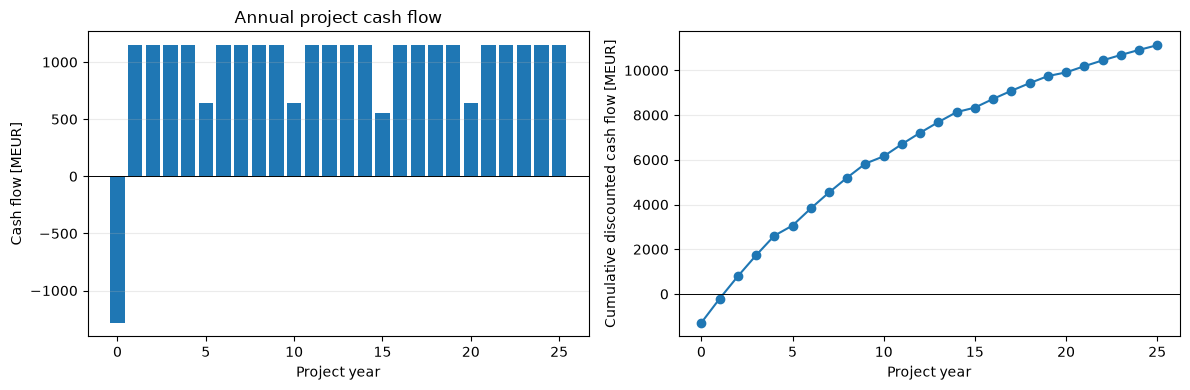

In [22]:
cashflows = pd.DataFrame({
    'Year': finance['finance_years'],
    'Revenue': finance['Revenue_dc_vec'] / 1e6,
    'OPEX': finance['OPEX_system_vec'] / 1e6,
    'Investment': finance['CAPEX_system_vec'] / 1e6,
    'Depreciation': finance['depreciation_vec'] / 1e6,
    'Tax': finance['taxes_vec'] / 1e6,
    'Net residual': finance['residual_value_vec'] / 1e6,
    'Cash flow': finance['cashflow_vec'] / 1e6,
    'Discounted cash flow': finance['discounted_cashflow_vec'] / 1e6,
    'Cumulative discounted cash flow': finance['cumulative_discounted_cashflow_vec'] / 1e6,
}).set_index('Year')
print('Annual cash flows [MEUR]; depreciation affects tax only:')
display(cashflows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(cashflows.index, cashflows['Cash flow'])
axes[0].set(xlabel='Project year', ylabel='Cash flow [MEUR]', title='Annual project cash flow')
axes[1].plot(cashflows.index, cashflows['Cumulative discounted cash flow'], marker='o')
axes[1].set(xlabel='Project year', ylabel='Cumulative discounted cash flow [MEUR]')
for ax in axes:
    ax.axhline(0, color='black', linewidth=0.7)
    ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()


In [23]:
# Independent NPV: rebuild the net cash flow from displayed financial components.
independent_cashflow = (
    finance['Revenue_dc_vec'] - finance['OPEX_system_vec'] - finance['taxes_vec']
    - finance['CAPEX_system_vec'] + finance['residual_value_vec'])
manual_npv = sum(float(cf) / (1 + effective['project_discount_rate']) ** year
                 for year, cf in enumerate(independent_cashflow))
np.testing.assert_allclose(manual_npv, finance['NPV_system'], rtol=1e-12, atol=1e-6)
print(f'Independent discounted-cash-flow NPV: EUR {manual_npv:,.2f}')

# Compare the complete native HPP finance component with the new component.
# For this isolated HPP-only parity check, BOTH exclude DC costs and replacements.
# Zero tax/inflation/residual and year-zero initial payment are required.
display(pd.DataFrame([compare_native_hpp_finance(case['inputs'], effective)]))

# Discount the already-validated investment schedule, including replacements.
discount = (1 + effective['project_discount_rate']) ** finance['finance_years']
manual_capex_pv = np.sum(finance['CAPEX_system_vec'] / discount)
manual_replacement_pv = np.sum(
    (finance['replacement_battery_vec'] + finance['replacement_it_vec']) / discount)
np.testing.assert_allclose(manual_capex_pv, finance['CAPEX_PV_system'])
np.testing.assert_allclose(manual_replacement_pv, finance['CAPEX_replacement_PV_system'])
np.testing.assert_allclose(manual_npv / manual_capex_pv, finance['NPV_over_PV_CAPEX_system'])
print('Discounted lifetime CAPEX [EUR]:', manual_capex_pv)
print('Discounted replacement CAPEX [EUR]:', manual_replacement_pv)
print('NPV / discounted lifetime CAPEX:', finance['NPV_over_PV_CAPEX_system'])


Independent discounted-cash-flow NPV: EUR 11,124,913,664.08


,integrated_hpp_only_npv,native_hpp_only_npv,difference
0,1.301660e+10,1.301660e+10,0.0


Discounted lifetime CAPEX [EUR]: 2247983259.092195
Discounted replacement CAPEX [EUR]: 967349486.6856472
NPV / discounted lifetime CAPEX: 4.948841864849826


In [24]:
from hydesign.finance.finance_simple_datacenter import validate_saved_assembly_finance

integrated = validate_saved_assembly_finance(case, config_path)
assert integrated['dispatch_unchanged']
print('Integrated assembly: all scalar and vector finance outputs match Phase 1.')
print('Saved dispatch unchanged; reliability and physical validation passed.')
display(pd.Series(integrated['economics']).reindex([
    'CAPEX_system', 'CAPEX_lifetime_system', 'CAPEX_PV_system',
    'CAPEX_replacement_PV_system', 'NPV_over_PV_CAPEX_system', 'OPEX_system', 'Revenue_dc', 'NPV_system',
    'NPV_over_CAPEX_system', 'IRR_system', 'payback_years',
    'discounted_payback_years', 'annualized_cost_hpp', 'annualized_cost_dc',
    'net_annual_value_system']))



Fixed parameters on the site
-------------------------------
longitude = 11.813965
latitude = 55.39776
altitude = 42.0
Integrated assembly: all scalar and vector finance outputs match Phase 1.
Saved dispatch unchanged; reliability and physical validation passed.


CAPEX_system                   1.280634e+09
CAPEX_lifetime_system          3.398578e+09
CAPEX_PV_system                2.247983e+09
CAPEX_replacement_PV_system    9.673495e+08
NPV_over_PV_CAPEX_system       4.948842e+00
OPEX_system                    1.471562e+07
Revenue_dc                     1.162251e+09
NPV_system                     1.112491e+10
NPV_over_CAPEX_system          8.687038e+00
IRR_system                     8.805241e-01
payback_years                  1.115986e+00
discounted_payback_years       1.207693e+00
annualized_cost_hpp            4.453910e+07
annualized_cost_dc             1.626774e+08
net_annual_value_system        9.550343e+08
dtype: float64

IRR is calculated from the actual cash-flow vector even when NPV is negative. Multiple cash-flow sign changes can make IRR nonunique; NPV remains the valuation reference. Payback is the first interpolated cumulative recovery and can be followed by a later decline when equipment is replaced. Undefined IRR/payback is shown as NaN.

Tax follows native phased finance: positive EBIT only, no tax refunds or loss carryforward. Depreciation is straight-line for each purchase. Residual proceeds, if configured, are net of disposal tax. No degradation, internal PPA, or optimization penalty enters these cash flows. The saved run files remain untouched.
